In [ ]:
# In [1]: Imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from geopy.distance import geodesic
from scipy.optimize import curve_fit
from scipy.spatial.distance import pdist # Import pdist for fast calculation
import pyarrow as pa

In [ ]:
# In [2]: Load and Prepare Data
# Load the pre-processed data
merged_gdf = pd.read_feather('../data/processed/merged_gdf.feather', use_threads=False)
merged_gdf = gpd.GeoDataFrame(merged_gdf, geometry=gpd.points_from_xy(merged_gdf.longitude, merged_gdf.latitude), crs='EPSG:4326')

pd.set_option('display.max_columns', None)  # Show all columns when printing DataFrames
# show do collumn

print(merged_gdf[['do_']])

        do_
0      12.4
1       3.2
2       8.7
3       4.4
4       3.9
...     ...
41341   9.5
41342   9.0
41343   9.0
41344   8.3
41345   8.5

[41346 rows x 1 columns]


In [ ]:
# Filter for bottom layer and drop rows with no DO value
# This is the base DataFrame for the analysis
df = merged_gdf[
    (merged_gdf['saisuipoin'] == 2)
].dropna(subset=['do_']).copy()

print(f"Prepared {len(df)} total data points for analysis.")

# In [3]: Calculate All Pairwise Distances and Semivariances (Grouped by Time)

all_distances = []
all_semivariance = []

# Group data based on season and year
grouped = df.groupby(['season', 'year'])

print(f"Processing {len(grouped)} time groups...")

for (season, year), group in grouped:
    # Skip groups that are too small to have pairs
    if len(group) < 2:
        continue

    # Get locations and values for this group
    locations = group[['latitude', 'longitude']].values
    do_values = group['do_'].values

    # --- Use pdist for fast, vectorized calculation *within* each group ---
    
    # Calculate all pairwise geographic distances (in km)
    distances_km = pdist(locations, metric=lambda u, v: geodesic(u, v).km)
    
    # Calculate all pairwise semivariances (0.5 * (diff^2))
    # We use pdist with 'sqeuclidean' which is (a-b)^2, then multiply by 0.5
    semivar = 0.5 * pdist(do_values[:, np.newaxis], metric='sqeuclidean')
    # -------------------------------------------------------------------
    
    # Add the results from this group to the global lists
    all_distances.append(distances_km)
    all_semivariance.append(semivar)

# Combine all results into single large arrays
distances = np.concatenate(all_distances)
semivariance = np.concatenate(all_semivariance)

print("All pairwise calculations complete.")



In [32]:
# ...existing code...
def get_unique_distances_by_year(df, target_year, metric='geodesic'):
    """
    Return unique pairwise distances for points in df for target_year.
    This computes pairwise distances only among points in that year (memory-efficient).
    """
    mask = df['year'] == target_year
    coords = df.loc[mask]
    if len(coords) < 2:
        return np.array([])

    # Use lat/lon geodesic distances if geometry is available
    try:
        pts = np.column_stack((coords.geometry.x, coords.geometry.y))
    except Exception:
        # fallback to explicit lon/lat columns if geometry missing
        pts = np.column_stack((coords['longitude'].values, coords['latitude'].values))

    if metric == 'geodesic':
        from geopy.distance import geodesic
        dists = pdist(pts, metric=lambda u, v: geodesic((u[1], u[0]), (v[1], v[0])).km)
    else:
        from scipy.spatial.distance import pdist as _pdist
        dists = _pdist(pts)  # Euclidean on projected coords

    return np.unique(dists)
# ...existing code...

# print one of the unique distances for testing
unique_dists_2022 = get_unique_distances_by_year(df, 2022)
print(f"Unique distances for 2022: {unique_dists_2022}")
print(len(unique_dists_2022))

Unique distances for 2022: [  0.           0.8067847    1.47062852 ... 427.99651338 428.8746201
 430.1603992 ]
7989


In [ ]:
# In [4]: Fit Model and Visualize Correlogram
# This section is the same as the second half of your 'In [18]'

# --- Step 3: Fit the Gaussian Variogram Model ---
def gaussian_variogram_model(h, a, c):
    # c * (1 - exp(-(h^2 / a^2)))
    return c * (1 - np.exp(-(h**2) / (a**2)))

# We provide an initial guess [a=50km, c=variance] to help the fitter
initial_guess = [50, np.var(df['do_'].values)]
params, _ = curve_fit(gaussian_variogram_model, distances, semivariance, p0=initial_guess)

fit_range_param = params[0] # This is 'a'
fit_sill = params[1]        # This is 'c'

print(f"--- Fit Results ---")
print(f"Fitted Sill (c): {fit_sill:.2f}")
print(f"Fitted Range Parameter (a): {fit_range_param:.2f} km")


--- Fit Results ---
Fitted Sill (c): 1.20
Fitted Range Parameter (a): 71.87 km


c:\Users\reyha\Documents\Master\東京大学\Colleag season 2\Masters thesis\Seto_Inland_sea_Analysis\.venv\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


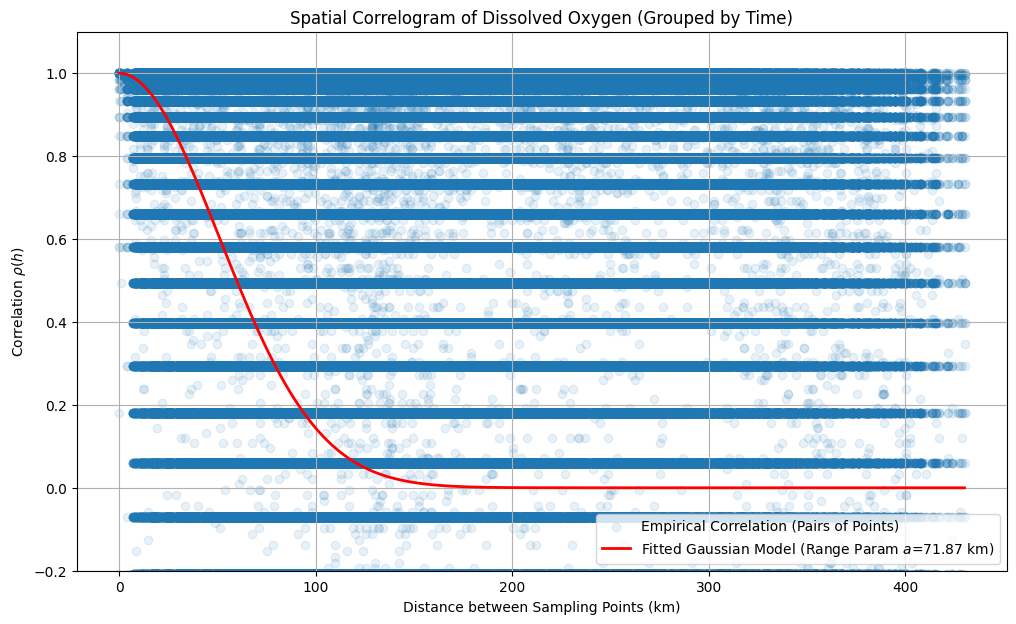

In [33]:
# --- Step 4: Transform Data and Model for Correlogram Plot ---
# corr = 1 - (semivariance / sill)
corr_cloud = 1 - (semivariance / fit_sill)

# Define the pure Gaussian *Correlation* Model: rho(h) = e^-(h^2/a^2)
def gaussian_correlation_model(h, a):
    return np.exp(-(h**2) / (a**2))

# Generate x-values for the fitted curve
x_fit = np.linspace(0, max(distances), 200)
# Calculate y-values for the fitted *correlation* curve
y_fit = gaussian_correlation_model(x_fit, fit_range_param)

# --- Step 5: Visualize the Correlogram ---
plt.figure(figsize=(12, 7))

# Plot the empirical correlation cloud (alpha=0.3 is good, 0.01 might be too light)
plt.scatter(distances, corr_cloud, alpha=0.1, label='Empirical Correlation (Pairs of Points)')

# plot the data from 2022 for testing
# plt.scatter(distances[year == 2022], corr_cloud[year == 2022], alpha=0.5, label='2022 Data')

# Plot the fitted Gaussian correlation model
plt.plot(x_fit, y_fit, 'r-', linewidth=2, 
         label=f'Fitted Gaussian Model (Range Param $a$={fit_range_param:.2f} km)')

# Add labels and title
plt.title('Spatial Correlogram of Dissolved Oxygen (Grouped by Time)')
plt.xlabel('Distance between Sampling Points (km)')
plt.ylabel('Correlation $\\rho(h)$')
plt.grid(True)
plt.ylim(-0.2, 1.1)
plt.legend()
plt.show()

In [38]:
# In [5]: Create and Plot the Binned (Empirical) Correlogram

print("Starting binned correlogram calculation...")

# --- Step 1: Define Bins ---
BIN_WIDTH = 1  # (km) You can adjust this. 10-20 km is usually a good starting point.
max_dist = np.max(distances)
bins = np.arange(0, max_dist + BIN_WIDTH, BIN_WIDTH)

# --- Step 2: Put All Pairwise Data into a DataFrame for Easy Binning ---
# This combines our two big arrays into a single structure
pair_data = pd.DataFrame({
    'distance': distances,
    'semivariance': semivariance
})

# Create a new column 'dist_bin' that assigns each row to a bin
# We use the 'right' label to label the bin by its upper edge
pair_data['dist_bin'] = pd.cut(pair_data['distance'], bins=bins, right=True)

# --- Step 3: Calculate the Average for Each Bin ---
# Group by the bins and calculate the mean distance and mean semivariance for each
binned_data = pair_data.groupby('dist_bin').agg(
    binned_distance=('distance', 'mean'),
    binned_semivariance=('semivariance', 'mean')
).dropna() # Drop any bins that had no points

# --- Step 4: Transform Binned Semivariance to Correlation ---
# We use the *same* sill calculated from the full dataset
binned_correlation = 1 - (binned_data['binned_semivariance'] / fit_sill)

print(f"Calculated averages for {len(binned_data)} distance bins.")

# show first few rows of binned data for verification
print(binned_data.head())
print(binned_correlation.head())


Starting binned correlogram calculation...
Calculated averages for 418 distance bins.
            binned_distance  binned_semivariance
dist_bin                                        
(0.0, 1.0]         0.806785             0.061750
(1.0, 2.0]         1.470629             0.029250
(3.0, 4.0]         3.921249             0.118664
(6.0, 7.0]         6.995965             1.058708
(7.0, 8.0]         7.539960             1.514652
dist_bin
(0.0, 1.0]    0.948346
(1.0, 2.0]    0.975533
(3.0, 4.0]    0.900738
(6.0, 7.0]    0.114396
(7.0, 8.0]   -0.266999
Name: binned_semivariance, dtype: float64


C:\Users\reyha\AppData\Local\Temp\ipykernel_6984\16458696.py:23: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  binned_data = pair_data.groupby('dist_bin').agg(


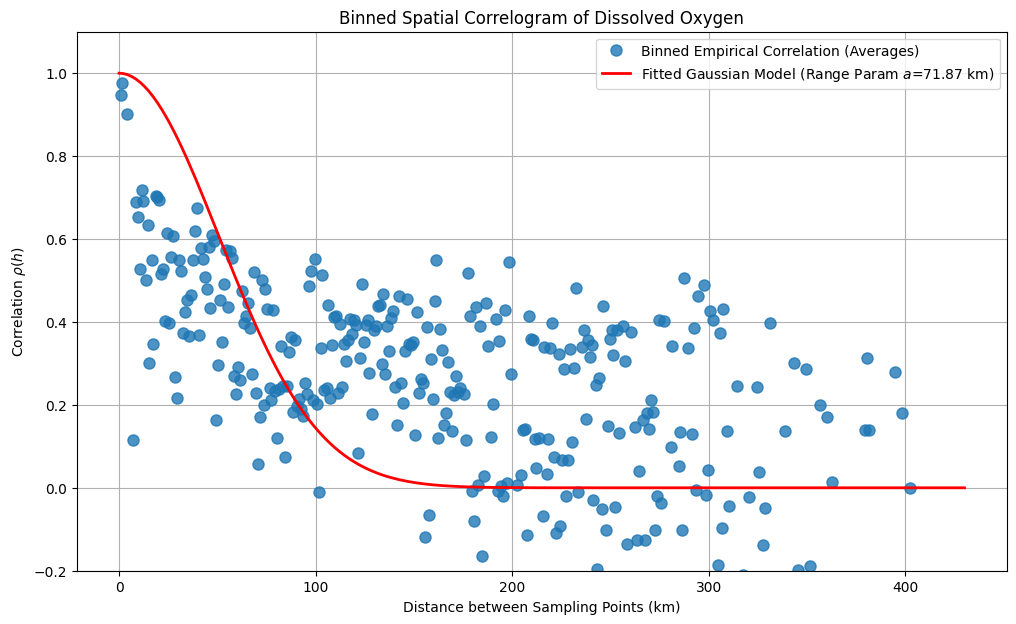

: 

In [ ]:

# --- Step 5: Plot the Binned Correlogram ---
plt.figure(figsize=(12, 7))

# Plot the new binned data as large, clear points
plt.plot(
    binned_data['binned_distance'], 
    binned_correlation, 
    'o',
    markersize=8, 
    alpha=0.8,
    label='Binned Empirical Correlation (Averages)'
)

# Plot the *exact same* fitted model from the previous plot on top
plt.plot(
    x_fit, 
    y_fit, 
    'r-', 
    linewidth=2, 
    label=f'Fitted Gaussian Model (Range Param $a$={fit_range_param:.2f} km)'
)

# Add labels and title
plt.title('Binned Spatial Correlogram of Dissolved Oxygen')
plt.xlabel('Distance between Sampling Points (km)')
plt.ylabel('Correlation $\\rho(h)$')
plt.grid(True)
plt.ylim(-0.2, 1.1)
plt.legend()
plt.show()